In [1]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Load the password from the .env file (one folder up)
load_dotenv("../.env")

# Connect to PostgreSQL
engine = create_engine(os.getenv("DATABASE_URL"))

# Load the whole orders table into a pandas DataFrame
df = pd.read_sql("SELECT * FROM orders", engine)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (9994, 21)


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   row_id         9994 non-null   int64  
 1   order_id       9994 non-null   str    
 2   order_date     9994 non-null   object 
 3   ship_date      9994 non-null   object 
 4   ship_mode      9994 non-null   str    
 5   customer_id    9994 non-null   str    
 6   customer_name  9994 non-null   str    
 7   segment        9994 non-null   str    
 8   country        9994 non-null   str    
 9   city           9994 non-null   str    
 10  state          9994 non-null   str    
 11  postal_code    9994 non-null   str    
 12  region         9994 non-null   str    
 13  product_id     9994 non-null   str    
 14  category       9994 non-null   str    
 15  sub_category   9994 non-null   str    
 16  product_name   9994 non-null   str    
 17  sales          9994 non-null   float64
 18  quantity       9994

In [3]:
# Dates: object -> datetime (so we can group by month/year)
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"]  = pd.to_datetime(df["ship_date"])

# Money columns: Decimal/object -> float (so we can calculate fast)
for col in ["sales", "discount", "profit"]:
    df[col] = df[col].astype(float)

df.dtypes

row_id                   int64
order_id                   str
order_date       datetime64[s]
ship_date        datetime64[s]
ship_mode                  str
customer_id                str
customer_name              str
segment                    str
country                    str
city                       str
state                      str
postal_code                str
region                     str
product_id                 str
category                   str
sub_category               str
product_name               str
sales                  float64
quantity                 int64
discount               float64
profit                 float64
dtype: object

In [5]:
# 1) Fully identical rows
print("Duplicate rows:", df.duplicated().sum())

# 2) Same order line without row_id (row_id is always unique, so ignore it)
cols = [c for c in df.columns if c != "row_id"]
print("Duplicates ignoring row_id:", df.duplicated(subset=cols).sum())

Duplicate rows: 0
Duplicates ignoring row_id: 1


In [7]:
dupes = df[df.duplicated(subset=cols, keep=False)]
dupes[["row_id", "order_id", "order_date", "product_name", "sales", "quantity", "profit"]]

,row_id,order_id,order_date,product_name,sales,quantity,profit
3406,3406,US-2014-150119,2014-04-23,Global Leather Highback Executive Chair with P...,281.372,2,-12.0588
3407,3407,US-2014-150119,2014-04-23,Global Leather Highback Executive Chair with P...,281.372,2,-12.0588


In [9]:
df[["sales", "quantity", "discount", "profit"]].describe().round(2)

,sales,quantity,discount,profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


In [11]:
q1 = df["sales"].quantile(0.25)
q3 = df["sales"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

outliers = df[df["sales"] > upper]
print(f"Upper limit: {upper:.2f}")
print(f"Outliers:    {len(outliers)} rows ({len(outliers)/len(df):.1%})")

outliers.sort_values("sales", ascending=False)[["product_name", "sub_category", "sales", "quantity", "profit"]].head(5)

Upper limit: 498.93
Outliers:    1167 rows (11.7%)


,product_name,sub_category,sales,quantity,profit
2698,Cisco TelePresence System EX90 Videoconferenci...,Machines,22638.480,6,-1811.0784
6826,Canon imageCLASS 2200 Advanced Copier,Copiers,17499.950,5,8399.9760
8153,Canon imageCLASS 2200 Advanced Copier,Copiers,13999.960,4,6719.9808
2624,Canon imageCLASS 2200 Advanced Copier,Copiers,11199.968,4,3919.9888
4191,Canon imageCLASS 2200 Advanced Copier,Copiers,10499.970,3,5039.9856


                    sales    profit
category                           
Technology       836154.0  145455.0
Furniture        742000.0   18451.0
Office Supplies  719047.0  122491.0


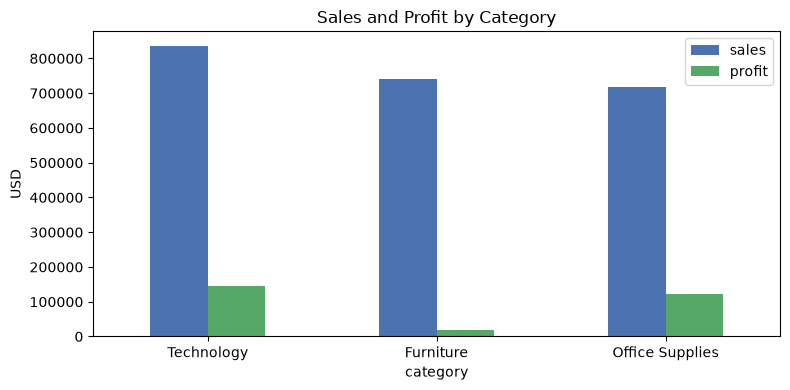

In [13]:
import matplotlib.pyplot as plt

by_cat = df.groupby("category")[["sales", "profit"]].sum().sort_values("sales", ascending=False)
print(by_cat.round(0))

by_cat.plot(kind="bar", figsize=(8, 4), color=["#4C72B0", "#55A868"])
plt.title("Sales and Profit by Category")
plt.ylabel("USD")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

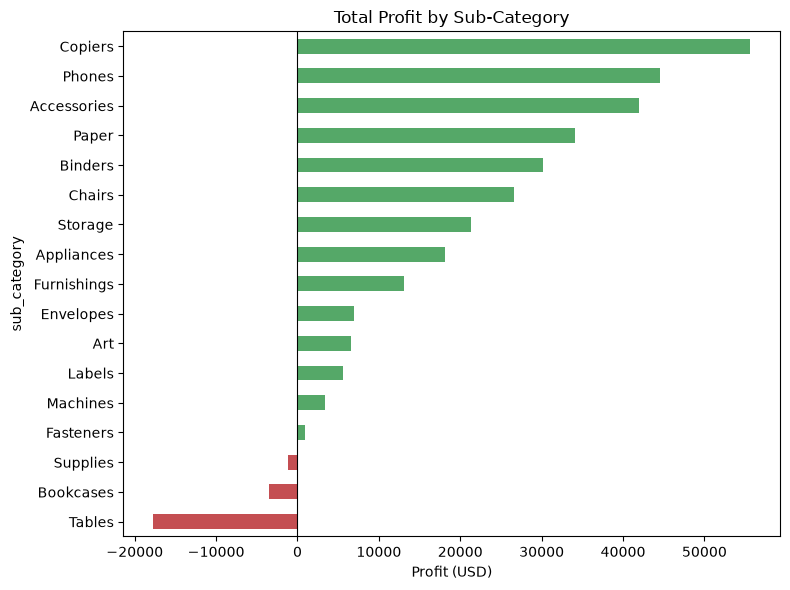

In [15]:
by_sub = df.groupby("sub_category")["profit"].sum().sort_values()

colors = ["#C44E52" if p < 0 else "#55A868" for p in by_sub]
by_sub.plot(kind="barh", figsize=(8, 6), color=colors)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit (USD)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

          orders  avg_profit
discount                    
0.00        4798       66.90
0.10          94       96.06
0.15          52       27.29
0.20        3657       24.70
0.30         227      -45.68
0.32          27      -88.56
0.40         206     -111.93
0.45          11     -226.65
0.50          66     -310.70
0.60         138      -43.08
0.70         418      -95.87
0.80         300     -101.80


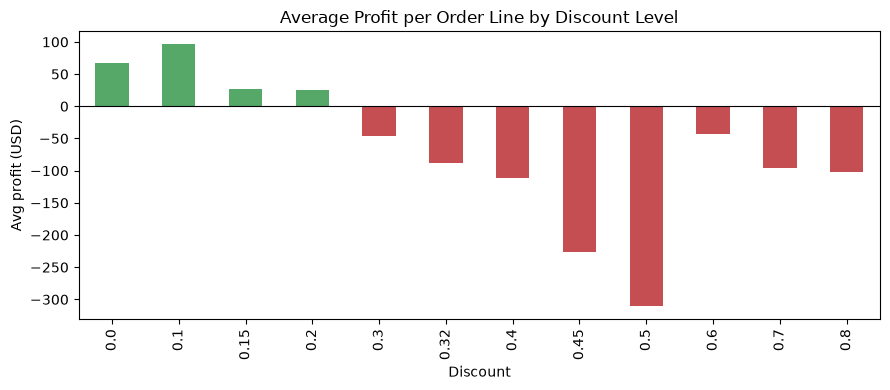

In [17]:
disc = df.groupby("discount").agg(orders=("profit", "size"),
                                  avg_profit=("profit", "mean")).round(2)
print(disc)

disc["avg_profit"].plot(kind="bar", figsize=(9, 4),
    color=["#C44E52" if p < 0 else "#55A868" for p in disc["avg_profit"]])
plt.title("Average Profit per Order Line by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Avg profit (USD)")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

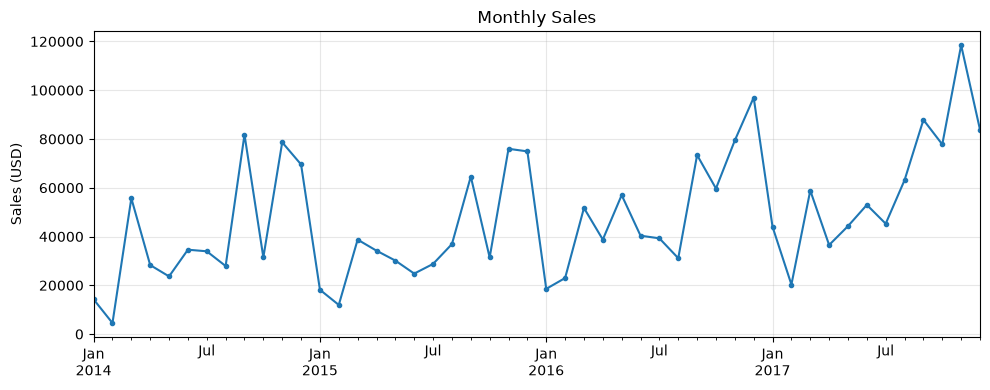

order_date
2014    484247.0
2015    470533.0
2016    609206.0
2017    733215.0
Name: sales, dtype: float64


In [19]:
monthly = df.set_index("order_date").resample("ME")["sales"].sum()

monthly.plot(figsize=(10, 4), marker="o", markersize=3)
plt.title("Monthly Sales")
plt.ylabel("Sales (USD)")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

yearly = df.groupby(df["order_date"].dt.year)["sales"].sum().round(0)
print(yearly)

            sales    profit  margin_%
region                               
West     725458.0  108418.0      15.0
East     678781.0   91523.0      14.0
South    391722.0   46749.0      12.0
Central  501240.0   39706.0       8.0


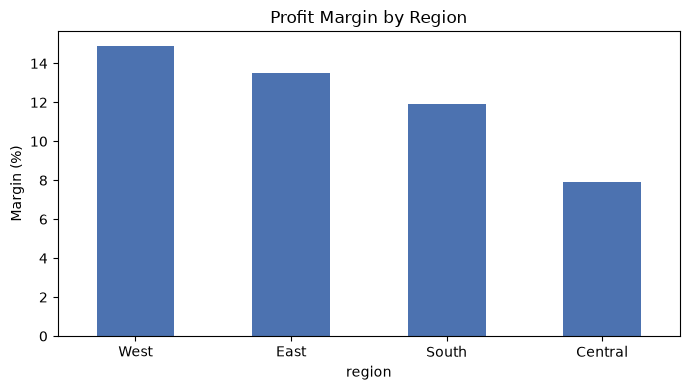

In [20]:
by_region = df.groupby("region").agg(sales=("sales", "sum"), profit=("profit", "sum"))
by_region["margin_%"] = (by_region["profit"] / by_region["sales"] * 100).round(1)
by_region = by_region.sort_values("margin_%", ascending=False)
print(by_region.round(0))

by_region["margin_%"].plot(kind="bar", figsize=(7, 4), color="#4C72B0")
plt.title("Profit Margin by Region")
plt.ylabel("Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Key Findings

**Data quality**
- 9,994 rows, 21 columns, **no missing values**
- Found and removed **1 hidden duplicate** (identical order line with a different `row_id`) → 9,993 rows
- Large sales outliers (Machines, Copiers) and negative profits are **real business cases**, not errors → kept

**Business insights**
1. **Furniture has a profit problem:** sales similar to the other categories, but only ≈2.5% margin (Technology ≈17%).
2. **Tables and Bookcases lose money:** they are the main reason for Furniture's low profit.
3. **Discounts above 20% destroy profit:** from 30% discount on, the average order line is unprofitable.
4. **Sales grow and are seasonal:** ≈ +50% from 2014 to 2017, with peaks in September, November and December.
5. **Central region underperforms:** ≈8% margin vs. ≈15% in the West.

**Recommendations**
- Limit discounts to **max. 20%**, especially for Tables and Bookcases
- Review pricing of loss-making sub-categories
- Plan stock and staff for the Q4 peak
- Investigate the discount policy in the Central region

Saved!


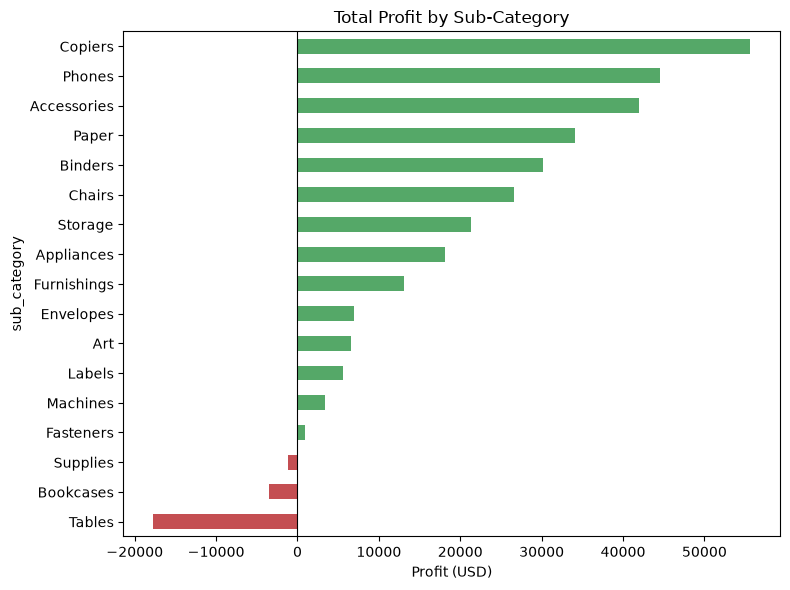

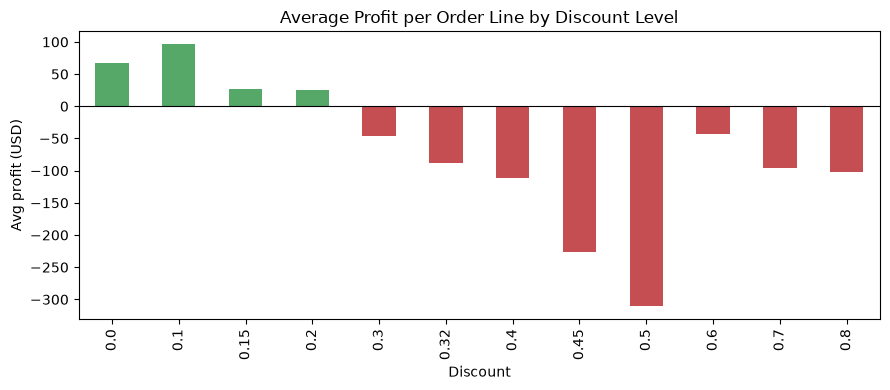

In [21]:
os.makedirs("../images", exist_ok=True)

# Image 1: profit by sub-category
fig, ax = plt.subplots(figsize=(8, 6))
by_sub.plot(kind="barh", ax=ax, color=["#C44E52" if p < 0 else "#55A868" for p in by_sub])
ax.set_title("Total Profit by Sub-Category")
ax.set_xlabel("Profit (USD)")
ax.axvline(0, color="black", linewidth=0.8)
fig.tight_layout()
fig.savefig("../images/profit_by_subcategory.png", dpi=150)

# Image 2: discount vs profit
fig, ax = plt.subplots(figsize=(9, 4))
disc["avg_profit"].plot(kind="bar", ax=ax,
    color=["#C44E52" if p < 0 else "#55A868" for p in disc["avg_profit"]])
ax.set_title("Average Profit per Order Line by Discount Level")
ax.set_xlabel("Discount")
ax.set_ylabel("Avg profit (USD)")
ax.axhline(0, color="black", linewidth=0.8)
fig.tight_layout()
fig.savefig("../images/discount_vs_profit.png", dpi=150)

print("Saved!")